# 4. Modeling: Pelatihan Model Tunggal LightGBM Classifier Teroptimasi

Sesuai metodologi **CRISP-DM** (*Cross-Industry Standard Process for Data Mining*), tahap **Modeling** berfokus secara ketat pada:
1. Perancangan arsitektur model pembelajaran mesin (*Gradient Boosted Decision Trees*) dengan **12 Fitur Inti** (7 band BOA Sentinel-2 + 5 indeks biofisik terarah mutual).
2. Penerapan konfigurasi **hiperparameter teroptimasi & regularisasi anti-overfitting** (`max_depth`, `num_leaves`, `min_child_samples`, `subsample`, `colsample_bytree`, `reg_alpha`, `reg_lambda`) guna menjaga performa model tetap objektif dan tidak *overfitting* terhadap korelasi spasial lokal.
3. Pelatihan (*training / fitting*) model utama pada **data latih piksel 10m (`train_pixels.csv`)** dan model pembanding pada **data latih poligon (`train_data.csv`)**.
4. Validasi performa internal menggunakan **Stratified 5-Fold Cross-Validation** pada data latih.
5. Analisis tingkat kepentingan fitur spektral (*feature importance*) untuk membuktikan efektivitas 5 indeks biofisik baru.
6. Serialisasi artefak model terlatih dan metadata terstruktur ke dalam direktori `models/`.

> **Catatan Metodologi CRISP-DM:**
> Seluruh pengujian pada data uji independen (*unseen test data*), pembuatan matriks konfusi (*confusion matrix*), kurva ROC-AUC, dan verifikasi standar akurasi BIG (≥ 80%) **sepenuhnya berada pada Tahap 5 (Evaluation)** guna mencegah kebocoran data (*data leakage*).

In [1]:
import os
import json
import joblib
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import lightgbm as lgb
from sklearn.model_selection import StratifiedKFold, cross_val_score

# pengaturan lingkungan dan visualisasi
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 11

print('[OK] Library Pemodelan LightGBM berhasil dimuat.')


[OK] Library Pemodelan LightGBM berhasil dimuat.


## 4.1 Pemuatan Data Latih dan Konfigurasi Validasi Silang (Stratified 5-Fold CV)

Memuat dataset latih dari Tahap 3 (Data Preparation):
- **Data Piksel (`train_pixels.csv`)**: 8.429 sampel piksel 10m sebagai basis utama pelatihan model.
- **Data Poligon (`train_data.csv`)**: 173 sampel poligon rata-rata sebagai pembanding zonasi.
- **12 Fitur Inti Spektral**:
  - 7 Band BOA Sentinel-2: `B02` (Blue), `B03` (Green), `B04` (Red), `B08` (NIR), `B8A` (Narrow NIR), `B11` (SWIR-1), `B12` (SWIR-2).
  - 5 Indeks Biofisik Terarah (*Mutual Disambiguation*): `REMI` (Mangrove vs Hutan), `NDVI` (Vegetasi Darat), `IBI` (Bangunan vs Tanah Kering), `MNDWI` (Sawah Berair & Lengas), `NDWI` (Perairan Murni).

In [2]:
# direktori data latih
data_dir = os.path.join('..', '3-data_preparation', 'prepared_data')
train_pixels_df = pd.read_csv(os.path.join(data_dir, 'train_pixels.csv'))
train_poly_df = pd.read_csv(os.path.join(data_dir, 'train_data.csv'))

# 12 fitur spektral inti
feature_cols = [
    'B02', 'B03', 'B04', 'B08', 'B8A', 'B11', 'B12',
    'REMI', 'NDVI', 'IBI', 'MNDWI', 'NDWI'
]

# ekstraksi matriks fitur dan target piksel
X_train_pix = train_pixels_df[feature_cols].values
y_train_pix = train_pixels_df['label'].values

# ekstraksi matriks fitur dan target poligon
X_train_poly = train_poly_df[feature_cols].values
y_train_poly = train_poly_df['label'].values

# nama kelas lulc
class_names = ['Bangunan', 'Pertanian', 'Perairan', 'Hutan Daratan', 'Hutan Mangrove']

print(f'Dimensi Matriks Piksel Latih : {X_train_pix.shape[0]} piksel x {X_train_pix.shape[1]} fitur')
print(f'Dimensi Matriks Poligon Latih: {X_train_poly.shape[0]} poligon x {X_train_poly.shape[1]} fitur')
print(f'Daftar 12 Fitur Inti        : {feature_cols}')
print(f'Distribusi Piksel per Kelas  : {dict(pd.Series(y_train_pix).value_counts().sort_index())}')

# konfigurasi stratified 5-fold cross validation
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
print('[OK] Stratified 5-Fold CV Generator siap digunakan.')


Dimensi Matriks Piksel Latih : 8429 piksel x 12 fitur
Dimensi Matriks Poligon Latih: 174 poligon x 12 fitur
Daftar 12 Fitur Inti        : ['B02', 'B03', 'B04', 'B08', 'B8A', 'B11', 'B12', 'REMI', 'NDVI', 'IBI', 'MNDWI', 'NDWI']
Distribusi Piksel per Kelas  : {0: np.int64(1805), 1: np.int64(2000), 2: np.int64(1522), 3: np.int64(1355), 4: np.int64(1747)}
[OK] Stratified 5-Fold CV Generator siap digunakan.


## 4.2 Pelatihan Model Utama LightGBM Tingkat Piksel 10m dengan Hiperparameter Teroptimasi & Regularisasi

Model utama **LightGBM Classifier** dilatih pada data latih piksel 10m (`train_pixels.csv`). Untuk mengatasi risiko *overfitting* yang sering terjadi pada data citra satelit akibat autokorelasi piksel tetangga, diterapkan konfigurasi hiperparameter teroptimasi berbasis regularisasi ketat:
- `n_estimators=120`: Jumlah pohon pembelajar sekuensial yang cukup untuk konvergensi stabil.
- `learning_rate=0.05`: Laju penyusutan gradien bertahap (*shrinkage*) agar penyesuaian bobot tidak melompati minimum optimal.
- `max_depth=6`: Pembatasan kedalaman pohon maksimum untuk mencegah penghafalan pola (*memorization*) derau spasial.
- `num_leaves=20`: Membatasi jumlah daun aktif lebih kecil dari $2^{\text{depth}}$ guna menghasilkan arsitektur pohon yang ramping dan generalis.
- `min_child_samples=35`: Mensyaratkan minimal 35 piksel pendukung pada setiap daun agar pohon tidak memisahkan piksel pencilan (*outlier*).
- `subsample=0.8`: Pengambilan acak 80% baris sampel latih pada setiap iterasi (*bagging*) guna meningkatkan variasi.
- `colsample_bytree=0.8`: Pengambilan acak 80% fitur pada setiap pembentukan pohon untuk mencegah dominasi band tertentu.
- `reg_alpha=0.2` & `reg_lambda=1.5`: Regularisasi L1 (Lasso) dan L2 (Ridge) pada bobot daun untuk meredam kompleksitas model.

In [3]:
# inisialisasi model lightgbm piksel dengan regularisasi anti-overfitting
lgb_pix = lgb.LGBMClassifier(
    n_estimators=120,
    learning_rate=0.05,
    num_leaves=20,
    max_depth=6,
    min_child_samples=35,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.2,
    reg_lambda=1.5,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)

# validasi silang (stratified 5-fold cv) pada data latih piksel
cv_scores_pix = cross_val_score(lgb_pix, X_train_pix, y_train_pix, cv=cv, scoring='accuracy')

# pelatihan penuh pada seluruh data latih piksel
lgb_pix.fit(X_train_pix, y_train_pix)

print('HASIL VALIDASI SILANG DATA LATIH PIKSEL (STRATIFIED 5-FOLD CV):')
print(f'- Rata-rata Akurasi CV        : {cv_scores_pix.mean()*100:.2f}%')
print(f'- Standar Deviasi (Stabilitas): ±{cv_scores_pix.std()*100:.2f}%')
print(f'- Skor Tiap Fold              : {[round(float(s)*100, 2) for s in cv_scores_pix]}')
print('[OK] Pelatihan Model LightGBM Piksel selesai dengan sukses.')


HASIL VALIDASI SILANG DATA LATIH PIKSEL (STRATIFIED 5-FOLD CV):
- Rata-rata Akurasi CV        : 95.12%
- Standar Deviasi (Stabilitas): ±0.55%
- Skor Tiap Fold              : [94.37, 94.54, 95.67, 95.49, 95.55]
[OK] Pelatihan Model LightGBM Piksel selesai dengan sukses.


## 4.3 Analisis Kepentingan Fitur Spektral (*Feature Importance*) Model Piksel

Mengevaluasi kontribusi relatif masing-masing dari 12 fitur spektral inti berdasarkan seberapa sering fitur tersebut digunakan untuk pemotongan pohon (*split importance*). Analisis ini membuktikan apakah 5 indeks biofisik terarah (REMI, NDVI, IBI, MNDWI, NDWI) aktif berkontribusi dalam pemisahan kelas tutupan lahan.

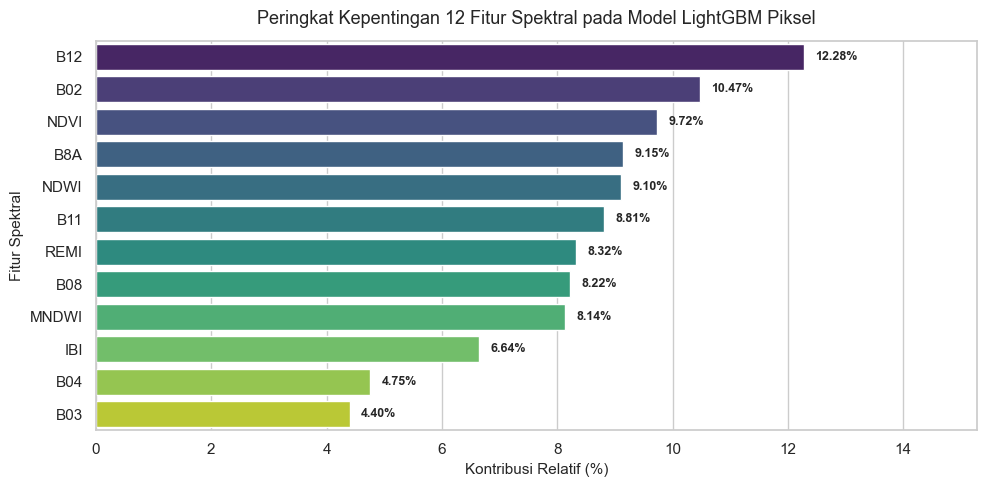

[OK] Tabel Kepentingan 12 Fitur Spektral (Model Piksel):


,Fitur,Importance,Kontribusi (%)
0,B12,1086,12.279512
1,B02,926,10.470375
2,NDVI,860,9.724107
3,B8A,809,9.147445
4,NDWI,805,9.102216
5,B11,779,8.808232
6,REMI,736,8.322026
7,B08,727,8.220262
8,MNDWI,720,8.141113
9,IBI,587,6.637268


In [4]:
# kalkulasi feature importance model piksel
fi_vals_pix = lgb_pix.feature_importances_
fi_df_pix = pd.DataFrame({
    'Fitur': feature_cols,
    'Importance': fi_vals_pix,
    'Kontribusi (%)': (fi_vals_pix / fi_vals_pix.sum()) * 100
}).sort_values(by='Kontribusi (%)', ascending=False).reset_index(drop=True)

# visualisasi peringkat kepentingan fitur spektral
plt.figure(figsize=(10, 5))
barplot = sns.barplot(data=fi_df_pix, x='Kontribusi (%)', y='Fitur', palette='viridis')
for i, v in enumerate(fi_df_pix['Kontribusi (%)']):
    barplot.text(v + 0.2, i, f'{v:.2f}%', va='center', fontweight='bold', fontsize=9)

plt.title('Peringkat Kepentingan 12 Fitur Spektral pada Model LightGBM Piksel', fontsize=13, pad=12)
plt.xlabel('Kontribusi Relatif (%)', fontsize=11)
plt.ylabel('Fitur Spektral', fontsize=11)
plt.xlim(0, fi_df_pix['Kontribusi (%)'].max() + 3.0)
plt.tight_layout()
plt.show()
plt.close()

print('[OK] Tabel Kepentingan 12 Fitur Spektral (Model Piksel):')
display(fi_df_pix)


## 4.4 Pelatihan Model Pembanding Poligon & Analisis Kepentingan Fitur

Melatih model pembanding pada tingkat poligon (`train_data.csv`, 173 sampel) dengan parameter yang disesuaikan untuk ukuran dataset poligon (`min_child_samples=5`). Model ini berfungsi sebagai pembanding performa agregat kawasan.

In [5]:
# inisialisasi model lightgbm poligon
lgb_poly = lgb.LGBMClassifier(
    n_estimators=100,
    learning_rate=0.05,
    num_leaves=15,
    max_depth=5,
    min_child_samples=5,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    random_state=42,
    verbose=-1,
    n_jobs=-1
)

# validasi silang (stratified 5-fold cv) pada data latih poligon
cv_scores_poly = cross_val_score(lgb_poly, X_train_poly, y_train_poly, cv=cv, scoring='accuracy')

# pelatihan penuh pada seluruh data latih poligon
lgb_poly.fit(X_train_poly, y_train_poly)

print('HASIL VALIDASI SILANG DATA LATIH POLIGON (STRATIFIED 5-FOLD CV):')
print(f'- Rata-rata Akurasi CV        : {cv_scores_poly.mean()*100:.2f}%')
print(f'- Standar Deviasi (Stabilitas): ±{cv_scores_poly.std()*100:.2f}%')
print(f'- Skor Tiap Fold              : {[round(float(s)*100, 2) for s in cv_scores_poly]}')
print('[OK] Pelatihan Model LightGBM Poligon selesai dengan sukses.')


HASIL VALIDASI SILANG DATA LATIH POLIGON (STRATIFIED 5-FOLD CV):
- Rata-rata Akurasi CV        : 79.88%
- Standar Deviasi (Stabilitas): ±1.82%
- Skor Tiap Fold              : [80.0, 77.14, 82.86, 80.0, 79.41]
[OK] Pelatihan Model LightGBM Poligon selesai dengan sukses.


## 4.5 Serialisasi Artefak Model Terlatih dan Metadata Terstruktur

Menyimpan artefak model biner (`.pkl`) dan metadata terstruktur (`.json`) ke folder `models/`:
1. `model_lightgbm_piksel.pkl` & `metadata_lightgbm_piksel.json` (Model Piksel Utama Resolusi 10m).
2. `model_lightgbm_teroptimasi.pkl` & `metadata_lightgbm_teroptimasi.json` (Model Poligon Pembanding).
Artefak juga disinkronisasikan ke folder aplikasi `6-deployment` untuk mendukung aplikasi interaktif Streamlit.

In [6]:
# pembuatan direktori model
model_dir = 'models'
os.makedirs(model_dir, exist_ok=True)

pix_model_path = os.path.join(model_dir, 'model_lightgbm_piksel.pkl')
pix_meta_path = os.path.join(model_dir, 'metadata_lightgbm_piksel.json')

poly_model_path = os.path.join(model_dir, 'model_lightgbm_teroptimasi.pkl')
poly_meta_path = os.path.join(model_dir, 'metadata_lightgbm_teroptimasi.json')

# simpan model biner piksel dan poligon
joblib.dump(lgb_pix, pix_model_path)
joblib.dump(lgb_poly, poly_model_path)

# definisi metadata kelas target lulc
classes_info = {
    '0': {'nama_kelas': 'Bangunan', 'alias': 'Built-up', 'kode_warna': '#EF4444'},
    '1': {'nama_kelas': 'Lahan Pertanian', 'alias': 'Farmland', 'kode_warna': '#D97706'},
    '2': {'nama_kelas': 'Perairan', 'alias': 'Water Body', 'kode_warna': '#0284C7'},
    '3': {'nama_kelas': 'Hutan Daratan', 'alias': 'Terrestrial Forest', 'kode_warna': '#16A34A'},
    '4': {'nama_kelas': 'Hutan Mangrove', 'alias': 'Mangrove Forest', 'kode_warna': '#0D9488'}
}

# metadata terstruktur model piksel
pix_meta = {
    'label_file': 'model_lightgbm_piksel.pkl',
    'nama_model': 'LightGBM Pixel Classifier (Tuned & Regularized - 10m Resolution)',
    'paradigma': '1 Model Tunggal Teroptimasi Tingkat Piksel 10m',
    'arsitektur': 'Histogram-Based Gradient Boosted Decision Tree (LightGBM)',
    'hiperparameter': {
        'n_estimators': 120,
        'learning_rate': 0.05,
        'max_depth': 6,
        'num_leaves': 20,
        'min_child_samples': 35,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
        'reg_alpha': 0.2,
        'reg_lambda': 1.5
    },
    'jumlah_fitur': len(feature_cols),
    'daftar_fitur': feature_cols,
    'kelas_target': classes_info,
    'total_piksel_latih': len(X_train_pix),
    'rata_rata_akurasi_cv': float(cv_scores_pix.mean()),
    'standar_deviasi_cv': float(cv_scores_pix.std())
}

with open(pix_meta_path, 'w', encoding='utf-8') as f:
    json.dump(pix_meta, f, indent=2, ensure_ascii=False)

# metadata terstruktur model poligon
poly_meta = {
    'label_file': 'model_lightgbm_teroptimasi.pkl',
    'nama_model': 'LightGBM Classifier (Tuned Single Model - Polygon Level)',
    'arsitektur': 'Histogram-Based Gradient Boosted Decision Tree (LightGBM)',
    'paradigma': '1 Model Tunggal Teroptimasi',
    'hiperparameter': {
        'n_estimators': 100,
        'learning_rate': 0.05,
        'max_depth': 5,
        'num_leaves': 15,
        'min_child_samples': 5,
        'subsample': 0.8,
        'colsample_bytree': 0.8,
        'reg_alpha': 0.1,
        'reg_lambda': 1.0
    },
    'jumlah_fitur': len(feature_cols),
    'daftar_fitur': feature_cols,
    'kelas_target': classes_info,
    'n_sampel_latih': len(X_train_poly),
    'rata_rata_akurasi_cv': float(cv_scores_poly.mean()),
    'standar_deviasi_cv': float(cv_scores_poly.std())
}

with open(poly_meta_path, 'w', encoding='utf-8') as f:
    json.dump(poly_meta, f, indent=2, ensure_ascii=False)

# sinkronisasi otomatis artefak model ke direktori deployment
deploy_model_dir = os.path.join('..', '6-deployment', 'standalone_streamlit_app', 'models')
if os.path.exists(deploy_model_dir):
    shutil.copy2(pix_model_path, deploy_model_dir)
    shutil.copy2(pix_meta_path, deploy_model_dir)
    shutil.copy2(poly_model_path, deploy_model_dir)
    shutil.copy2(poly_meta_path, deploy_model_dir)
    print(f'[OK] Sinkronisasi artefak model ke {deploy_model_dir} berhasil.')

print(f'[OK] Disimpan: model_lightgbm_piksel.pkl ({os.path.getsize(pix_model_path)/1024:.1f} KB)')
print(f'[OK] Disimpan: metadata_lightgbm_piksel.json ({os.path.getsize(pix_meta_path)/1024:.1f} KB)')
print(f'[OK] Disimpan: model_lightgbm_teroptimasi.pkl ({os.path.getsize(poly_model_path)/1024:.1f} KB)')
print(f'[OK] Disimpan: metadata_lightgbm_teroptimasi.json ({os.path.getsize(poly_meta_path)/1024:.1f} KB)')
print(f'[SELESAI] Tahap Modeling selesai dengan sukses.')


[OK] Sinkronisasi artefak model ke ..\6-deployment\standalone_streamlit_app\models berhasil.
[OK] Disimpan: model_lightgbm_piksel.pkl (1062.9 KB)
[OK] Disimpan: metadata_lightgbm_piksel.json (1.4 KB)
[OK] Disimpan: model_lightgbm_teroptimasi.pkl (469.6 KB)
[OK] Disimpan: metadata_lightgbm_teroptimasi.json (1.4 KB)
[SELESAI] Tahap Modeling selesai dengan sukses.
